# The Weird Geometry of High-Dimensional Space

Our 3D spatial intuition falls apart when doing geometry in higher dimensions, where "volume," "distance," and "angle" stop behaving the way they do in 2D or 3D space. This is all just a consequence of basic formulas we already know, but the consequences are surprising at first.

[High-Dimensional Probability](https://www.math.uci.edu/~rvershyn/papers/HDP-book/HDP-book.html) is a surprisingly good, free book which gets into the details of this geometry from a probability perspective, with very few prerequisites.

This notebook walks through four examples. The whole thing is self-contained: it only needs `numpy` and `matplotlib`, both of which Colab has preinstalled, so you can just run the cells top to bottom, and play with the plots.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# A clean default style for the plots
plt.style.use('seaborn-v0_8-darkgrid')

# Fix the seed so the figures are reproducible
np.random.seed(0)

## 1. Volume concentrates near the surface

Where is the "inside" of a ball (i.e. sphere)? In 3D, a watermelon is mostly interior — the rind is a thin layer near the surface. That's no longer true in higher dimensions.

The volume of a $d$-dimensional ball of radius $R$ scales as $R^d$. So inside the unit ball (i.e. all points within distance 1 of the origin), an inner ball of radius $0.99$ holds a fraction $(0.99)^d$ of the total volume, and $(0.99)^d \to 0$ as $d \to \infty$. The interior empties out and the volume piles up against the surface.

For example, in $10d$, the sub-ball of radius $1/2$ occupies just $\frac{1}{2}^{10} \approx 0.001$ of the unit ball.

The figures below sample points uniformly inside the unit ball and show histograms of their distance from the center.

In [2]:
def sample_unit_ball(N, d):
    # To sample uniformly inside a d-dimensional ball: draw a Gaussian vector,
    # normalize it to get a uniform random direction, then scale by U**(1/d)
    # so the points spread out with the right radial density.
    directions = np.random.normal(0, 1, (N, d))
    directions /= np.linalg.norm(directions, axis=1, keepdims=True)
    radii = np.random.uniform(0, 1, N) ** (1.0 / d)
    return directions * radii[:, np.newaxis]

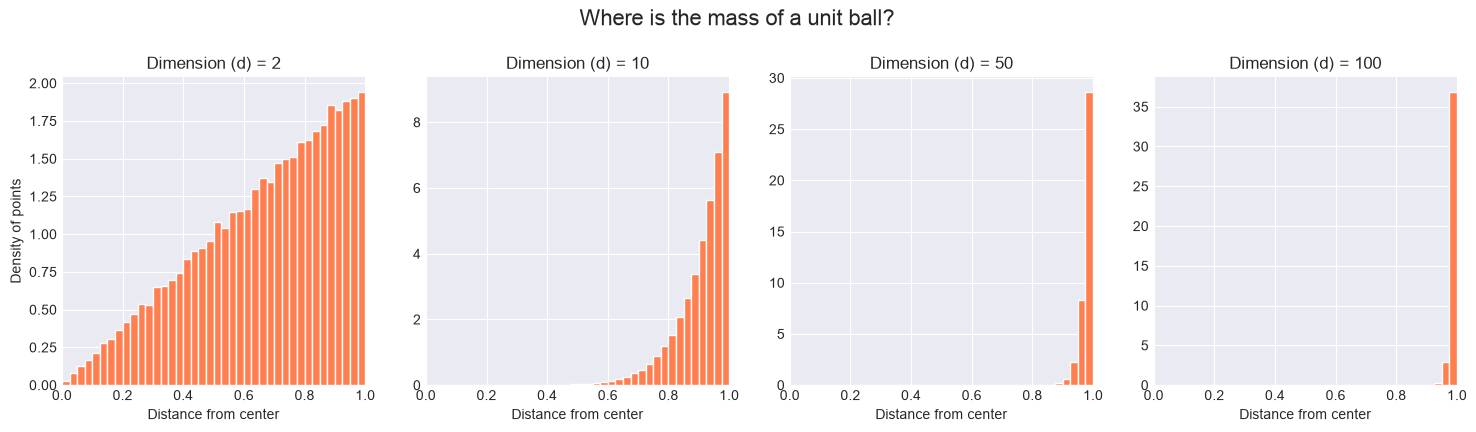

In [3]:
N = 50000
dimensions = [2, 10, 50, 100]

# Independent y-axes: the high-d histograms spike sharply near r=1, so a shared
# y-axis would flatten the lower-dimensional plots into nothing.
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=False)

for ax, d in zip(axes, dimensions):
    points = sample_unit_ball(N, d)
    distances = np.linalg.norm(points, axis=1)

    # range=(0, 1) pins the bins to the full axis. Without it, the bins auto-fit
    # the data range, so at high d they get crammed into a sliver near r=1 and
    # render as invisibly thin bars.
    ax.hist(distances, bins=40, range=(0, 1), color='coral',
            edgecolor='white', density=True)
    ax.set_title(f'Dimension (d) = {d}')
    ax.set_xlim(0, 1)
    ax.set_xlabel('Distance from center')

axes[0].set_ylabel('Density of points')
plt.suptitle('Where is the mass of a unit ball?', fontsize=16, y=1.05)
plt.show()

What the histograms show:

- In **2D**, the radial density grows linearly toward the edge (it's proportional to $r^{d-1}$).
- By **10D**, most of the mass has already moved out toward the surface.
- By **500D**, essentially every point sampled sits right up against the boundary. The interior is almost empty.

This is a recurring theme: in high dimensions, quantities that you'd expect to be spread out instead concentrate in a thin shell.

## 2. The spiky hypercube (kissing spheres)

This one is extremely weird.

Take a $d$-dimensional cube of side length 4 centered at the origin, so its walls sit at $\pm 2$ in every direction. Split it into $2^d$ subcubes of side 2 and drop a ball of radius 1 into each one — these are the "corner" spheres (in more than 3D the mathematically correct term is ball rather than sphere, but I guess the people who work on this stuff prefer not to call it "kissing balls"), centered at $(\pm 1, \pm 1, \dots, \pm 1)$.

Now put one more ball at the origin and inflate it until it just touches the corner balls. The distance from the origin to a corner ball's center is $\sqrt{d}$, and the corner balls have radius 1, so the central ball has radius $r = \sqrt{d} - 1$.

- In **2D**, the central circle is small and tucked safely inside the square.
- In **3D**, it's a bit bigger, but still comfortably inside the box.

The walls of the box are at distance 2 from the origin. So what happens to $r = \sqrt{d} - 1$ as $d$ grows?

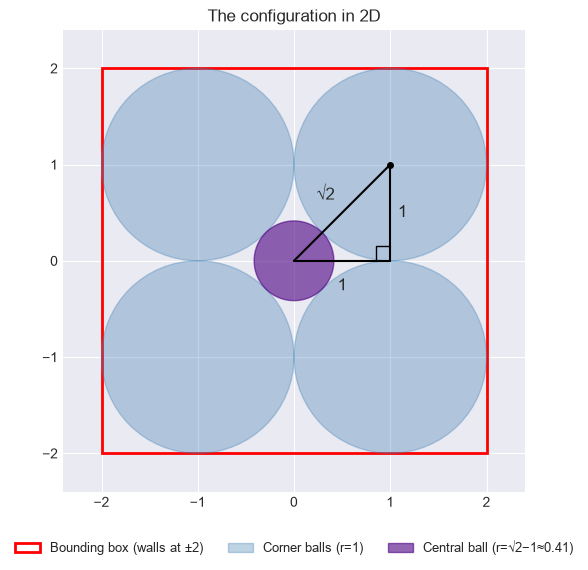

In [4]:
# The 2D picture: bounding box [-2, 2]^2, four corner balls of radius 1 centered
# at (±1, ±1), and the central ball that just touches them.
fig, ax = plt.subplots(figsize=(6, 6))

# Bounding box
ax.add_patch(plt.Rectangle((-2, -2), 4, 4, fill=False, edgecolor='red',
                           linewidth=2, label='Bounding box (walls at ±2)'))

# Corner balls (label only the first so the legend stays clean)
for i, (cx, cy) in enumerate([(-1, -1), (-1, 1), (1, -1), (1, 1)]):
    ax.add_patch(plt.Circle((cx, cy), 1, facecolor='steelblue', alpha=0.35,
                            edgecolor='steelblue',
                            label='Corner balls (r=1)' if i == 0 else None))

# Central ball, radius sqrt(2) - 1
r = np.sqrt(2) - 1
ax.add_patch(plt.Circle((0, 0), r, facecolor='indigo', alpha=0.6,
                        edgecolor='indigo',
                        label=f'Central ball (r=√2−1≈{r:.2f})'))

# Right triangle: the distance from the origin to the corner-ball center (1, 1)
# is the hypotenuse of a triangle with two legs of length 1, hence sqrt(2).
ax.plot([0, 1], [0, 0], color='black', linewidth=1.5)  # horizontal leg
ax.plot([1, 1], [0, 1], color='black', linewidth=1.5)  # vertical leg
ax.plot([0, 1], [0, 1], color='black', linewidth=1.5)  # hypotenuse = line of centers
ax.plot(1, 1, 'ko', markersize=4)                      # corner-ball center

ax.text(0.5, -0.18, '1', ha='center', va='top', fontsize=12)
ax.text(1.08, 0.5, '1', ha='left', va='center', fontsize=12)
ax.text(0.42, 0.6, '√2', ha='right', va='bottom', fontsize=12)

# Small square marking the right angle at (1, 0)
ax.plot([0.85, 0.85, 1.0], [0.0, 0.15, 0.15], color='black', linewidth=1)

ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 2.4)
ax.set_aspect('equal')
ax.set_title('The configuration in 2D')
# Legend below the axes so it doesn't cover the figure
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=3, fontsize=9)
plt.show()

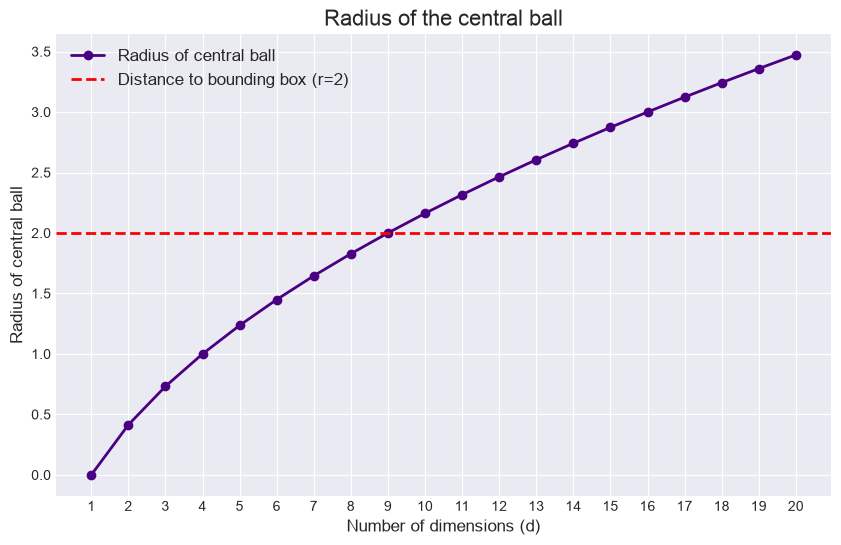

In [5]:
d_vals = np.arange(1, 21)
central_radius = np.sqrt(d_vals) - 1

plt.figure(figsize=(10, 6))
plt.plot(d_vals, central_radius, marker='o', linewidth=2, color='indigo',
         label='Radius of central ball')
plt.axhline(y=2, color='red', linestyle='--', linewidth=2,
            label='Distance to bounding box (r=2)')

plt.title('Radius of the central ball', fontsize=16)
plt.xlabel('Number of dimensions (d)', fontsize=12)
plt.ylabel('Radius of central ball', fontsize=12)
plt.xticks(d_vals)
plt.legend(fontsize=12)
plt.show()

At $d = 9$, the central ball exactly reaches the walls of the box. For $d > 9$, it extends past them, even though it's pinned in place by corner balls that are entirely inside the box.

The high-dimensional cube doesn't behave like a tidy solid block. When you think about going from 2D to 3D, the corners of the cube get "more pointy". The corner of a square takes up $\frac{1}{4}$ of the area around it, while the corner of a cube takes up only $\frac{1}{8}$ of the volume around it. 
 
As $d$ increases, the trend continues and the corners get so "pointy" and reach out so far compared to the distance to its faces that the cube is arguably more like a small body with $2^d$ long spikes attached.

## 3. Random vectors are nearly orthogonal

Picture two random arrows in 3D. They point in some arbitrary directions, and the angle between them could be just about anything.

In high dimensions this stops being true. Pick two random directions and they're almost always close to perpendicular ($90^\circ$). The code below samples a batch of random unit vectors in different dimensions and plots the histogram of their pairwise angles.

This example is very representative of the stuff in [High-Dimensional Probability](https://www.math.uci.edu/~rvershyn/papers/HDP-book/HDP-book.html).

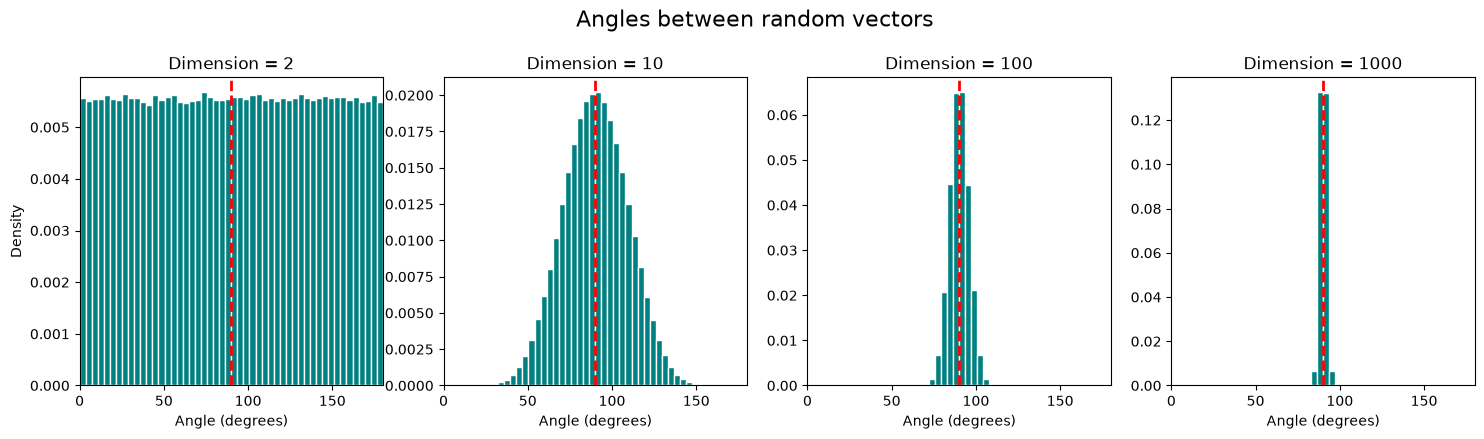

In [25]:
num_vectors = 1000
dims = [2, 10, 100, 1000]

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=False)

for ax, d in zip(axes, dims):
    # 1. Random vectors from a standard multivariate normal
    vecs = np.random.normal(0, 1, (num_vectors, d))

    # 2. Normalize to unit length (project onto the unit sphere)
    vecs /= np.linalg.norm(vecs, axis=1, keepdims=True)

    # 3. All pairwise dot products = cosines of the angles.
    #    Keep the upper triangle (each unordered pair once, no self-pairs).
    dot_products = vecs @ vecs.T
    upper_tri_indices = np.triu_indices(num_vectors, k=1)
    pair_dots = dot_products[upper_tri_indices]

    # 4. Convert to angles in degrees (clip to [-1, 1] for arccos's sake)
    angles = np.degrees(np.arccos(np.clip(pair_dots, -1.0, 1.0)))

    # 5. Plot
    ax.hist(angles, bins=50, range=(0, 180), color='teal', edgecolor='white', density=True)
    ax.axvline(90, color='red', linestyle='dashed', linewidth=2)
    ax.set_title(f'Dimension = {d}')
    ax.set_xlim(0, 180)
    ax.set_xlabel('Angle (degrees)')

axes[0].set_ylabel('Density')
plt.suptitle('Angles between random vectors', fontsize=16, y=1.05)
plt.show()

In 2D the angle is spread evenly across the range. As the dimension climbs, the distribution tightens sharply around $90^\circ$. Mathematicians have termed this "concentration of measure".

For a pair of unit vectors distributed uniformly at random, you can rotate the sphere so that without loss of generality and without changing the distribution, both are in the x-y plane and one of them is on the x axis, so the cosine of the angle between them is the coordinate first coordinate $x_1$ of the other vector. On a high-dimensional sphere the coordinates sum to one ($x_1^2 + \ldots + x_d^2 = 1$) and each $x_i$ has an identical distribution, so each $x_i^2$ has a mean of $1/d$. Thus by Cauchy-Schwarz $\mathbb{E}|x_i| \leq  \sqrt{\mathbb{E}x_i^2}$ = $1/\sqrt{d}$. The cosines cluster near 0 — i.e. the angles cluster near $90^\circ$ — and the spread shrinks like $1/\sqrt{d}$.

## 4. The Gaussian shell

We've all seen the 1D Gaussian bell curve. It's natural to assume that samples from a standard multivariate Gaussian $\mathcal{N}(0, I_d)$ look roughly the same way, like a dense cloud packed tightly around the origin and thinning out from there. It turns out this is not the case.

If $X \sim \mathcal{N}(0, I_d)$, then $\|X\|^2$ is a sum of $d$ independent squared standard normals, i.e. $\|X\|^2 = x_1^2 + \ldots + x_d^2$. Its mean is $\mathbb{E}\|X\|^2 = d$.

Some basic results from concentration of measure show that the squared distance from the origin "concentrates" (i.e. the distribution peaks out) around $d$, and the distance itself concentrates around $\sqrt{d}$, with fluctuations of order 1. See [High-Dimensional Probability](https://www.math.uci.edu/~rvershyn/papers/HDP-book/HDP-book.html) for why.

Strangely, almost no probability mass sits near the mean (the origin). Instead the points concentrate around a thin shell of radius $\approx \sqrt{d}$. While the origin is the single most likely place for any one point to land, the odds of one actually landing there become vanishingly small.

This is related to the phenomenon in example 1: while the probability density is highest in a small ball around the origin, there is almost no volume there for the random points to land in. As distance from the origin increases, greater volume overwhelms the relatively smaller probability density, until the tails of the distribution finally kick in and drive the density to zero. 

Plots: histograms of distances from the origin across a few dimensions.

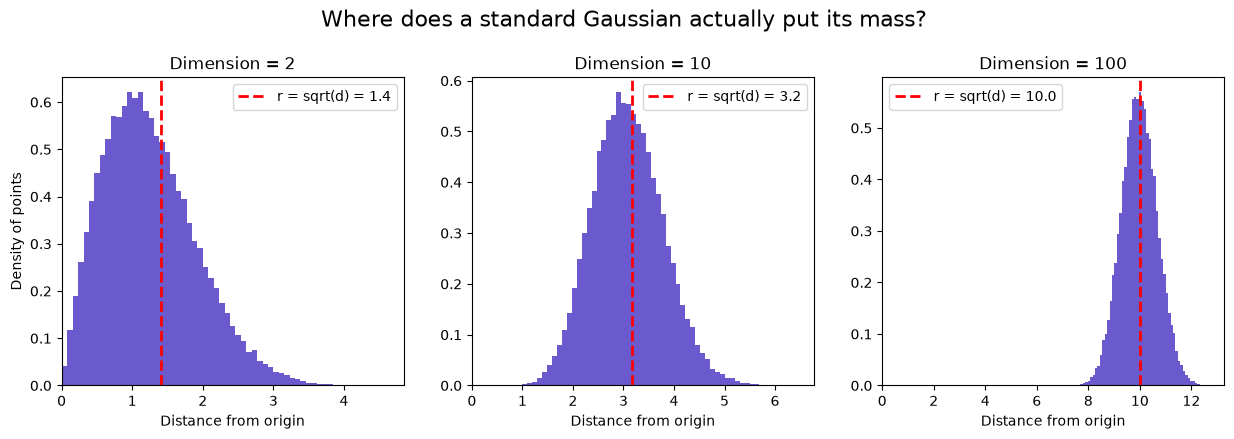

In [28]:
N = 50000
dimensions = [2, 10, 100]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)

for ax, d in zip(axes, dimensions):
    points = np.random.randn(N, d)           # N points from N(0, I_d)
    norms = np.linalg.norm(points, axis=1)   # distance of each point from the origin

    ax.hist(norms, bins=60, color='slateblue', density=True)
    ax.axvline(np.sqrt(d), color='red', linestyle='--', linewidth=2,
               label=f'r = sqrt(d) = {np.sqrt(d):.1f}')
    ax.set_title(f'Dimension = {d}')
    ax.set_xlabel('Distance from origin')
    ax.set_xlim(left=0)
    ax.legend()

axes[0].set_ylabel('Density of points')
plt.suptitle('Where does a standard Gaussian actually put its mass?', fontsize=16, y=1.05)
plt.show()

In 2D the distribution still leans toward the origin and looks roughly like the half-bell you'd expect. By $d = 100$ it's a tight bump sitting right at $r = 10 = \sqrt{100}$, with the origin far off to the left holding almost no mass. The Gaussian "blob" is really a Gaussian "soap bubble."

## Concentration of measure

In high dimensions, random distances stop being spread out and instead concentrate sharply around a typical value, with fluctuations that shrink relative to that value (often like $1/\sqrt{d}$).

- Points uniform in a ball pile up against the surface.
- A cube's corners stretch so far that its inscribed structure bursts through its own walls.
- Random directions are almost always perpendicular.
- A Gaussian's mass lives on a thin shell, not at its peak.

For as accessible and applicable as it is, concentration of measure is a relatively new field of math, developed mostly after the 1960s.